# CoTyle Dictionary-Controlled Texture Autoencoder — Colab Pro A100 Training

**Runtime Setup:** In Google Colab, go to **Runtime → Change runtime type → Hardware accelerator: GPU → GPU type: A100**.

In [3]:
# 1. Verify A100 GPU & VRAM
!nvidia-smi

Tue Nov  3 13:49:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P0             42W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [4]:
# 2. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# 3. Clone Repository (or pull latest if already cloned) & Install Dependencies
import os

REPO_URL = "https://github.com/rommaltser/codebook_encoder_decoder.git"
REPO_DIR = "/content/codebook_encoder_decoder"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
!pip install -q -r requirements.txt

Cloning into '/content/codebook_encoder_decoder'...
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 28 (delta 2), reused 28 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (28/28), 704.59 KiB | 1.18 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/codebook_encoder_decoder


In [6]:
# 4. Stage DTD Images to Local Colab NVMe SSD (/content/dtd/images) for 10x Faster Data Loading
# Reading 5,640 small JPGs from /content/ local SSD is ~15x faster than reading over Google Drive FUSE.
import os, glob, shutil

DRIVE_DATASET_PATH = "/content/drive/MyDrive/tau material/datasets/dtd-pseudo-labled-Qwen2.5-VL-32B-AWQ"
LOCAL_DTD_IMAGES = "/content/dtd/images"

assert os.path.exists(DRIVE_DATASET_PATH), f"Path not found in Drive: {DRIVE_DATASET_PATH}"
print("Found Drive dataset folder contents:", os.listdir(DRIVE_DATASET_PATH))

if not os.path.exists(LOCAL_DTD_IMAGES):
    os.makedirs("/content/dtd", exist_ok=True)
    drive_imgs_candidate = os.path.join(DRIVE_DATASET_PATH, "images")
    if os.path.isdir(drive_imgs_candidate):
        print("Copying images from Google Drive to local SSD /content/dtd/images ...")
        shutil.copytree(drive_imgs_candidate, LOCAL_DTD_IMAGES)
    else:
        print("Downloading official DTD dataset (dtd-r1.0.1.tar.gz) to local SSD /content/dtd ...")
        !wget -q https://www.robots.ox.ac.uk/~vgg/data/dtd/download/dtd-r1.0.1.tar.gz -O /content/dtd.tar.gz
        !tar -xzf /content/dtd.tar.gz -C /content/
        !rm -f /content/dtd.tar.gz

print("Total DTD categories on local SSD:", len(os.listdir(LOCAL_DTD_IMAGES)))

Found Drive dataset folder contents: ['imdb', 'labels', '_progress_raw.jsonl', 'images', 'README.md']
Copying images from Google Drive to local SSD /content/dtd/images ...
Total DTD categories on local SSD: 47


In [ ]:
# 5. Launch Two-Phase Training on A100 (Checkpoints Saved Directly to Google Drive)
# Set --num-clusters 6 (structural/surface only) or --num-clusters 8 (including chromatic_quality & hue)
%cd /content/codebook_encoder_decoder
!git pull origin main
!PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True python3 train.py \
  --config configs/colab_a100.yaml \
  --img-dir "/content/dtd/images" \
  --labels-json "/content/drive/MyDrive/tau material/datasets/dtd-pseudo-labled-Qwen2.5-VL-32B-AWQ" \
  --num-clusters 6 \
  --batch-size 32

In [7]:
# 5. Launch Two-Phase Training on A100 (Checkpoints Saved Directly to Google Drive)
# Set --num-clusters 6 (structural/surface only) or --num-clusters 8 (including chromatic_quality & hue)
!python3 train.py \
  --config configs/colab_a100.yaml \
  --img-dir "/content/dtd/images" \
  --labels-json "/content/drive/MyDrive/tau material/datasets/dtd-pseudo-labled-Qwen2.5-VL-32B-AWQ" \
  --num-clusters 6 \
  --batch-size 64

Loaded DTDTextureDataset with 5639 valid annotated textures across 6 clusters.
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100% 97.8M/97.8M [00:00<00:00, 239MB/s]
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16-3979

In [10]:
%cd /content/codebook_encoder_decoder
!git pull origin main

PHASE1_CKPT = "/content/drive/MyDrive/tau material/datasets/dtd-pseudo-labled-Qwen2.5-VL-32B-AWQ/checkpoints_cotyle/checkpoint_phase1_supervisor.pt"

!PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True python3 train.py \
  --config configs/colab_a100.yaml \
  --img-dir "/content/dtd/images" \
  --labels-json "/content/drive/MyDrive/tau material/datasets/dtd-pseudo-labled-Qwen2.5-VL-32B-AWQ" \
  --num-clusters 6 \
  --batch-size 32 \
  --resume "{PHASE1_CKPT}"

/content/codebook_encoder_decoder
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 7 (delta 4), reused 7 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 1.62 KiB | 832.00 KiB/s, done.
From https://github.com/rommaltser/codebook_encoder_decoder
 * branch            main       -> FETCH_HEAD
   a15f031..8f245de  main       -> origin/main
Updating a15f031..8f245de
Fast-forward
 configs/colab_a100.yaml |  3 ++-
 engine/trainer.py       | 36 +++++++++++++++++++++++-------------
 train_colab_a100.ipynb  | 21 ++++++++++++++++++---
 3 files changed, 43 insertions(+), 17 deletions(-)
Loaded DTDTextureDataset with 5639 valid annotated textures across 6 clusters.
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be remov

In [11]:
# 6. Resume Training (If a Colab Session Disconnects)
# Simply re-run cells 1-4 and run this cell:
CKPT_PATH = "/content/drive/MyDrive/tau material/datasets/dtd-pseudo-labled-Qwen2.5-VL-32B-AWQ/checkpoints_cotyle/checkpoint_latest.pt"
if os.path.exists(CKPT_PATH):
    !python3 train.py \
      --config configs/colab_a100.yaml \
      --resume "{CKPT_PATH}"

Loaded DTDTextureDataset with 5639 valid annotated textures across 6 clusters.
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/vgg.pth
Resumed from checkpoint '/content/drive/MyDrive/tau material/datasets/dtd-pseudo-labled-Qwen2.5-VL-32B-AWQ/checkpoints_cotyle/checkpoint_latest.pt

Edited [element_shape -> hexagonal (idx=6)] | Supervisor predicted: angular (idx=0) | Saved side-by-side (Original | Reconstructed | Edited) to: /content/edited_comparison.png


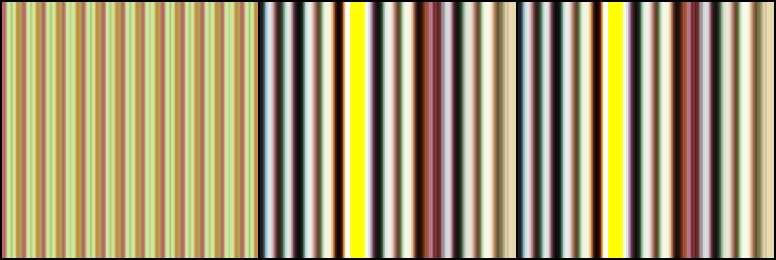

In [13]:
# 7. Test Single-Attribute Dictionary Swap on bubbly_0038 & Visualize with String Labels
%cd /content/codebook_encoder_decoder
!git pull origin main

from IPython.display import Image as IPyImage, display

test_img = "bubbly_0038.png"  # Auto-resolves to /content/dtd/images/bubbly/bubbly_0038.jpg
ckpt_path = "/content/drive/MyDrive/tau material/datasets/dtd-pseudo-labled-Qwen2.5-VL-32B-AWQ/checkpoints_cotyle/checkpoint_epoch_070.pt"

!python3 test_edit.py \
  --config configs/colab_a100.yaml \
  --checkpoint "{ckpt_path}" \
  --image "{test_img}" \
  --cluster element_shape \
  --word hexagonal \
  --output /content/edited_comparison.png

display(IPyImage("/content/edited_comparison.png"))